# 6장 차원 축소 part A

**범위:** 6.1 차원 축소 개요 · 6.2 PCA · 6.3 LDA  

- `scikit-learn` 내장 데이터만 사용하므로 별도 파일은 필요하지 않습니다.
- 제공된 시작 코드를 바탕으로 `TODO` 부분을 완성해주세요. 필요한 라이브러리나 변수는 추가하셔도 됩니다.
- 각 문항의 해석 질문은 실행 결과를 근거로 **2~3문장**으로 작성해주세요.


## 문제 1. Wine 데이터: 정보를 얼마나 유지하며 차원을 줄일 수 있을까?

Wine 데이터에는 **178개 샘플, 13개 수치 피처, 3개 클래스**가 있습니다.

**(a)** 13개 피처를 표준화한 뒤 PCA를 적용하세요. **누적 설명된 분산 비율이 처음으로 90% 이상**이 되는 최소 주성분 개수를 계산하고, 그때의 누적 설명된 분산 비율을 출력하세요.  
**(b)** (a)에서 찾은 개수만큼 주성분을 남겨 변환하고, 결과 배열의 모양을 출력하세요.  
**(c)** 주성분 개수가 2개일 때의 누적 설명된 분산 비율도 계산한 다음, (a)의 결과와 비교하여 **주성분을 많이 남길수록 얻는 점과 잃는 점**을 설명하세요.

힌트: `explained_variance_ratio_`, `np.cumsum`, `np.argmax`, `PCA(n_components=...)`

In [1]:
import numpy as np
from sklearn.datasets import load_wine
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

X, y = load_wine(return_X_y=True)
X_scaled = StandardScaler().fit_transform(X)

# TODO (a) 전체 주성분의 누적 설명된 분산 비율을 구하고 90% 기준 최소 차원 수를 출력하세요.
wine_pca= PCA()
wine_pca.fit(X_scaled)
cumulative= np.cumsum(wine_pca.explained_variance_ratio_)
#np.argmax(): 배열에서 가장 먼저 등장하는 True의 위치를 반환 
d90= np.argmax(cumulative>=0.9)
print('조건을 만족하는 최소 주성분 개수:', d90)
print('그때의 누적 설명된 분산 비율:', cumulative[d90-1])

# TODO (b) 최소 차원 수로 PCA 변환하고 변환 후 데이터의 shape를 출력하세요.
pca_90 = PCA(n_components=d90)
X_pca90= wine_pca.transform(X_scaled)
print('변환 후 shape:', X_pca90.shape)

# TODO (c) 주성분 2개의 누적 설명된 분산 비율을 출력하세요.
pca2 = PCA(n_components=2).fit(X_scaled)
print(f'주성분 2개의 누적 설명된 분산 비율: {pca2.explained_variance_ratio_.sum():.4f}')



조건을 만족하는 최소 주성분 개수: 7
그때의 누적 설명된 분산 비율: 0.8933679539739375
변환 후 shape: (178, 13)
주성분 2개의 누적 설명된 분산 비율: 0.5541


**해석 답안:**
주성분 개수가 2개일때보다 7개일 때 누적 설명 분산 비율이 더 큰 것을 확인할 수 있다. 
주성분을 많이 남길수록 누적 설명 분산 비율이 증가하여 원본 데이터의 정보를 더 많이 보존할 수 있지만, 차원 축소 효과가 감소하고 계산량과 저장 공간이 상대적으로 많이 필요하게 된다. 

## 문제 2. 유방암 진단 데이터: PCA가 분류 성능에 미치는 영향

Breast Cancer Wisconsin 데이터에는 **569개 샘플, 30개 입력 피처, 2개 클래스**가 있습니다. 동일한 `LogisticRegression` 모델을 **원본 피처**와 **PCA로 5개 주성분으로 변환한 피처**에 각각 적용하려고 합니다.

**(a)** 원본 피처와 PCA 변환 피처에 대해 각각 `StandardScaler`가 포함된 `Pipeline`을 만들고, **5-Fold 층화 교차 검증**으로 평균 정확도를 구하세요. (두 모델 모두 동일한 `StratifiedKFold` 사용)  
**(b)** 두 모델의 평균 정확도 차이를 **퍼센트포인트(%p)** 단위로 출력하세요. (PCA 모델 − 원본 모델)  
**(c)** PCA 모델의 정확도가 낮아지거나 높아지더라도, **PCA가 반드시 분류 성능을 개선하는 방법은 아닌 이유**를 발표의 핵심 개념으로 설명하세요.

조건: `random_state=42`, `n_splits=5`, `shuffle=True`로 고정하세요. PCA는 **Pipeline 내부**에 배치합니다.

힌트: `make_pipeline`, `cross_val_score`, `StratifiedKFold`

In [3]:
import numpy as np
from sklearn.datasets import load_breast_cancer
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.pipeline import make_pipeline

X, y = load_breast_cancer(return_X_y=True)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

#로지스티회귀모델을 원본피처, PCA로 변환한 피처에 각각 적용하기 

# TODO (a) 원본 모델 파이프라인과 PCA(5개) 모델 파이프라인을 만들고
model1 = make_pipeline(StandardScaler(), LogisticRegression())
pca_model= make_pipeline(StandardScaler(), PCA(n_components=5), LogisticRegression())

# 동일한 cv로 정확도를 비교하세요.
scores = cross_val_score(model1, X, y, cv=cv, scoring='accuracy')
pca_scores = cross_val_score(pca_model, X, y, cv=cv, scoring='accuracy')


# TODO (b) 두 평균 정확도의 차이를 %p로 출력하세요.
print('평균 정확도 차이 (%p):', f'{(np.mean(pca_scores)-np.mean(scores))*100:+.2f}')



평균 정확도 차이 (%p): -1.05


해석 : pca는 데이터의 분산을 최대한 보존하는 방향으로 차원을 축소한다. 하지만 분산이 큰 방향이 반드시 분류에 중요한 정보를 포함하는 것은 아니다. 따라서 차원 축소 과정에서 분류에 중요한 정보가 손실될 수 있으며, 반대로 불필요한 정보가 제거되어 성능이 향상될 수도 있다. 그러므로 pca가 반드시 분류 성능을 개선하는 방법은 아니다. 


## 문제 3. Wine 데이터: PCA와 LDA의 차원을 줄이는 기준 비교

문제 1의 Wine 데이터를 활용해 **13차원 → 2차원**으로 축소한 뒤, PCA와 LDA 결과를 비교하세요.

**(a)** `train_test_split(test_size=0.3, stratify=y, random_state=42)`로 학습·평가 데이터를 분리하고, 학습 데이터로만 `StandardScaler`를 학습해 두 데이터에 적용하세요. 그다음 **PCA(2개)**와 **LDA(2개)**를 각각 학습 데이터로 학습하여 학습·평가 데이터를 변환하세요. 결과 배열의 모양을 출력하세요. LDA에는 클래스 레이블을 입력해야 합니다.  
**(b)** 각각의 2차원 학습 데이터에 `LogisticRegression`을 학습하고, 평가 데이터 정확도를 출력하세요.  
**(c)** 두 방법이 서로 다른 결과를 내는 이유를 **사용하는 레이블과 축을 선택하는 기준**이라는 두 관점에서 설명하세요. 정확도가 높게 나온 방법이 모든 데이터에서 우월하다고 단정할 수 있는지도 덧붙이세요.

힌트: `LinearDiscriminantAnalysis(n_components=2)`, `fit_transform(X_train_scaled, y_train)`, `accuracy_score`

In [10]:
from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

X, y = load_wine(return_X_y=True)

# TODO (a) 데이터를 분할하고 학습 데이터 기준으로 표준화한 뒤,
# PCA 및 LDA로 각각 2차원 학습/평가 데이터를 만드세요.
#데이터 분할 
X_train, X_test, y_train, y_test= train_test_split(X, y, test_size=0.3, stratify=y, random_state=42)

#학습 데이터 기준으로 표준화 
scaler=StandardScaler()
X_train_scaled= scaler.fit_transform(X_train)
X_test_scaled= scaler.fit_transform(X_test)

#pca를 이용한 2차원 축소 
pca= PCA(n_components=2)
X_train_pca= pca.fit_transform(X_train)
X_test_pca= pca.transform(X_test)

#lda를 이용한 2차원 축소 
lda= LinearDiscriminantAnalysis(n_components=2)
X_train_lda=lda.fit_transform(X_train_scaled, y_train) #지도학습 기법이므로, 학습데이터에 정답 레이블이 필요함. 
X_test_lda= lda.transform(X_test_scaled)

# 변환된 데이터 모양 출력
print("PCA 학습 데이터:", X_train_pca.shape)
print("PCA 평가 데이터:", X_test_pca.shape)
print("LDA 학습 데이터:", X_train_lda.shape)

# TODO (b) 변환된 데이터에 각각 로지스틱 회귀 모델을 학습시켜 평가 정확도를 출력하세요.
logistic_pca= LogisticRegression(max_iter=2000)
logistic_pca.fit(X_train_pca, y_train)
pred_pca= logistic_pca.predict(X_test_pca)
print("PCA 정확도:", accuracy_score(y_test, pred_pca))

logistic_lda= LogisticRegression(max_iter=2000)
logistic_lda.fit(X_train_lda, y_train)
pred_lda = logistic_lda.predict(X_test_lda)
print("LDA 정확도:", accuracy_score(y_test, pred_lda))


PCA 학습 데이터: (124, 2)
PCA 평가 데이터: (54, 2)
LDA 학습 데이터: (124, 2)
PCA 정확도: 0.6851851851851852
LDA 정확도: 0.9629629629629629


**해석 답안:**

PCA는 정답 레이블을 사용하지 않고 데이터의 전체 분산을 최대한 보존하는 방향으로 차원을 축소하는 비지도학습 기법이다. 반면 LDA는 정답 레이블을 사용하여 클래스 간 분산을 최대화하고 클래스 내 분산을 최소화하는 방향으로 차원을 축소하는 지도학습 기법이다.

따라서 분류가 목적이라면 클래스 간 구분을 직접 고려하는 LDA가 더 높은 정확도를 보일 수 있다. 하지만 PCA도 데이터의 주요 정보를 보존하거나 노이즈를 제거하여 높은 정확도를 보일 수 있으므로, 어느 방법이 더 우수한지는 실제 평가 데이터의 정확도를 비교하여 판단해야 한다.

# **문제 4. SVD를 이용한 행렬 분해 및 복원**

## **4-1. 행렬 분해**

SVD를 이용하여 5x5 행렬 a를 분해 해주세요.

In [11]:
import numpy as np
from numpy.linalg import svd

np.random.seed(10)
a = np.random.randn(5, 5)

U, Sigma, Vt = svd(a)

print('Origianl matrix a:\n', np.round(a, 3))
print('\nU matrix:\n', np.round(U, 3))
print('\nSigma matrix:\n', np.round(Sigma, 3))
print('\nV transpose matrix:\n', np.round(Vt, 3))

Origianl matrix a:
 [[ 1.332  0.715 -1.545 -0.008  0.621]
 [-0.72   0.266  0.109  0.004 -0.175]
 [ 0.433  1.203 -0.965  1.028  0.229]
 [ 0.445 -1.137  0.135  1.485 -1.08 ]
 [-1.978 -1.743  0.266  2.385  1.124]]

U matrix:
 [[-0.34   0.653 -0.057  0.53   0.416]
 [ 0.06  -0.106 -0.18  -0.506  0.835]
 [-0.116  0.668 -0.086 -0.655 -0.322]
 [ 0.291  0.183  0.923 -0.065  0.161]
 [ 0.884  0.286 -0.325  0.174  0.008]]

Sigma matrix:
 [4.077 2.543 1.952 1.107 0.3  ]

V transpose matrix:
 [[-0.531 -0.549  0.225  0.595  0.106]
 [ 0.295  0.211 -0.615  0.643  0.276]
 [ 0.548 -0.346  0.097  0.259 -0.71 ]
 [ 0.373 -0.698 -0.185 -0.327  0.483]
 [-0.437 -0.218 -0.726 -0.242 -0.419]]


## **4-2. 행렬 복원**

분해한 행렬을 복원해 주세요.

In [12]:
# Sigma를 대각행렬로 변환
Sigma_mat = np.diag(Sigma)

# U, Sigma, Vt를 이용하여 원본 행렬 복원
a_ = np.dot(np.dot(U, Sigma), Vt)

print(np.round(a_, 3))

[-0.959 -3.948 -2.82  -1.923 -0.242]


## **4-3. 위 코드에서 Sigma의 shape를 작성해 주세요.**


(5,)

# **문제 5. Truncated SVD를 이용한 차원 축소**
다음은 Wine 데이터셋에 Truncated SVD를 적용하여 13차원 데이터를 2차원으로 축소하는 코드입니다.

\## 답안 ## 에 알맞은 코드를 작성해 주세요.

## **5-1. 차원 축소**

2차원으로 축소해주세요.

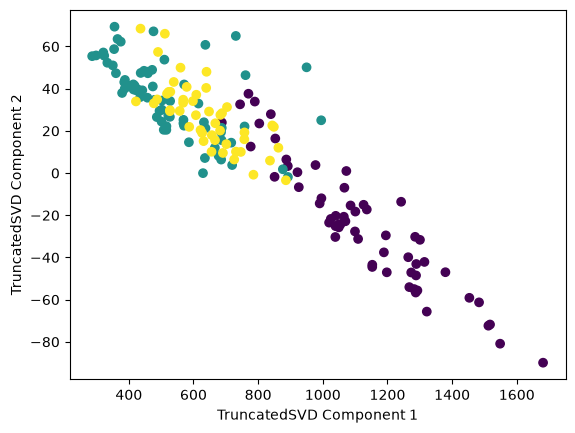

In [13]:
from sklearn.decomposition import TruncatedSVD
from sklearn.datasets import load_wine
import matplotlib.pyplot as plt
%matplotlib inline

wine = load_wine()
wine_ftrs = wine.data

tsvd = TruncatedSVD(n_components=2)

tsvd.fit(wine_ftrs)
wine_tsvd = tsvd.transform(wine_ftrs)

# 시각화
plt.scatter(
    x=wine_tsvd[:, 0],
    y=wine_tsvd[:, 1],
    c=wine.target
)
plt.xlabel('TruncatedSVD Component 1')
plt.ylabel('TruncatedSVD Component 2')
plt.show()

# **문제 6. SVD와 Truncated SVD 비교**

#### **SVD와 Truncated SVD의 차이점을 사용되는 특이값의 개수와 행렬 복원 시 정보 손실여부를 중심으로 서술해 주세요.**

답 :
SVD는 행렬을 분해할 때 모든 특이값을 사용하며, 모든 특이값을 이용해 행렬을 복원하면 원래 행렬을 손실 없이 복원할 수 있다.
Truncated SVD는 특이값 중 큰 값부터 일부만 선택하여 사용한다. 따라서 차원을 축소할 수 있지만, 선택하지 않은 특이값에 해당하는 정보가 손실되므로 원래 행렬을 복원할 때 정보 손실이 발생한다.

## 다른 차원의 축소 기법들 개념 복습

# **문제 7.**  
 Discord에 공유된 핸즈온 머신러닝pdf의 '8.6 다른 차원축소 기법들(p. 295 ~ 296)' 혹은 Week10 발표 ppt 속 '#06 다른 차원의 축소 기법들' 파트 내용을 참고해서 랜덤 투영 알고리즘, MDS, ISomap, t-SNE 중 하나의 차원 축소 기법을 골라 간단히 설명하세요.

답 : 
랜덤 투영 알고리즘은 랜덤한 선형 투영을 사용하여 데이터를 저차원 공간에 투영하는 방법으로, 실제 거리를 비교적 잘 보존한다는 장점이 있다.

더 많은 차원을 삭제할수록 정보 손실이 커지고 거리의 왜곡도 증가한다. 주어진 허용 오차를 초과하지 않도록 거리를 보존하는 데 필요한 최소 차원 수를 결정하는 방정식이 함수에 구현되어 있다.

## 여러가지 차원 축소 기법들 적용하기

# 문제 8. Dimensionality Reduction for Beginners
8-1)  `PCA`, `MDS`, `t-SNE`각각의 코드를 완성해 실행하세요.   
8-2) 세 기법의 차이를 간단히 서술하세요.

In [14]:
#데이터 로딩하기

%matplotlib inline

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, BoundaryNorm
import matplotlib.patches as mpatches
import seaborn as sns
from sklearn.datasets import load_breast_cancer #Loading the full DataSet From Sklearn Library

# Breast cancer dataset
cancer = load_breast_cancer()
(X_canc, y_canc) = load_breast_cancer(return_X_y = True)

In [15]:
#시각화 함수 만들기

def plot_labelled_scatter(X, y, class_labels,s):
    num_labels = len(class_labels)
    x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
    y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1

    marker_array = ['o', '^', '*']
    color_array = ['#FFFF00', '#00AAFF', '#000000', '#FF00AA']
    cmap_bold = ListedColormap(color_array)
    bnorm = BoundaryNorm(np.arange(0, num_labels + 1, 1), ncolors=num_labels)
    plt.figure(figsize=s)

    plt.scatter(X[:, 0], X[:, 1], s=80, c=y, cmap=cmap_bold, norm = bnorm, alpha = 0.4, edgecolor='black', lw = 1)
    sp = plt.gca().spines
    sp['top'].set_visible(False)
    sp['right'].set_visible(False)

    plt.grid(which='both',color='lightslategrey',alpha=0.3)

    plt.xlim(x_min, x_max)
    plt.ylim(y_min, y_max)

    h = []
    for c in range(0, num_labels):
        h.append(mpatches.Patch(color=color_array[c], label=class_labels[c]))
    plt.legend(handles=h,fontsize=15,frameon=False)

8-1) `PCA`, `MDS`, `t-SNE` 코드 완성하기

PCA 코드 완성하기

In [22]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

canc_norm = StandardScaler().fit(X_canc).transform(X_canc)

pca = PCA(n_components = 2).fit(canc_norm)

canc_pca = pca.transform(canc_norm)

print('Number of Features in Breat Cancer DataSet Before PCA : {}\n\nNumber of Features in Breast Cancer DataSet After PCA : {}'
      .format(canc_norm.shape[1], canc_pca.shape[1]))

Number of Features in Breat Cancer DataSet Before PCA : 30

Number of Features in Breast Cancer DataSet After PCA : 2


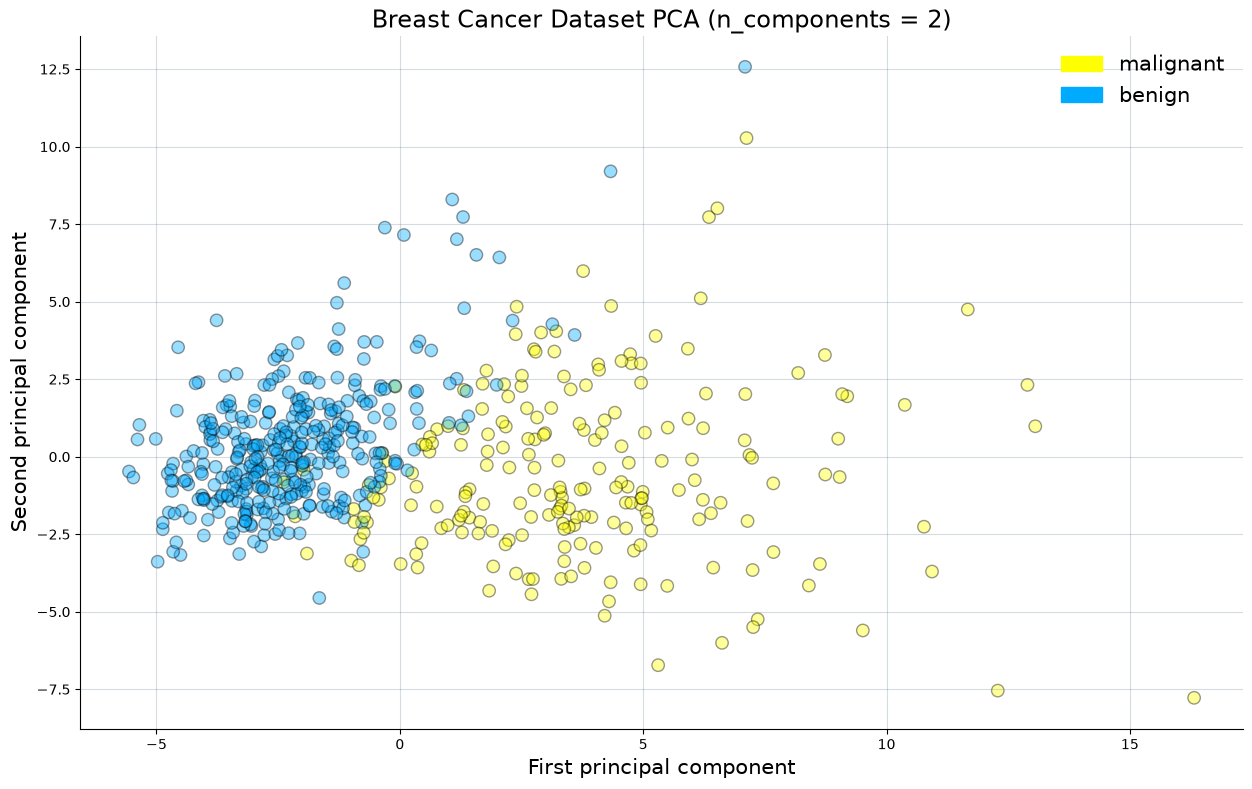

In [23]:
#앞서 만든 함수 사용
plot_labelled_scatter(canc_pca, y_canc, ['malignant', 'benign'],(15,9))

#Labelling
plt.xlabel('First principal component',fontsize=15)
plt.ylabel('Second principal component',fontsize=15)
plt.title('Breast Cancer Dataset PCA (n_components = 2)',fontsize=17);

MSD 코드 완성하기

c:\Users\0510n\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\manifold\_mds.py:735: FutureWarning: The default value of `init` will change from 'random' to 'classical_mds' in 1.10. To suppress this warning, provide some value of `init`.
  warnings.warn(


Number of Features in Breat Cancer DataSet Before MDS : 30

Number of Features in Breast Cancer DataSet After MDS : 2


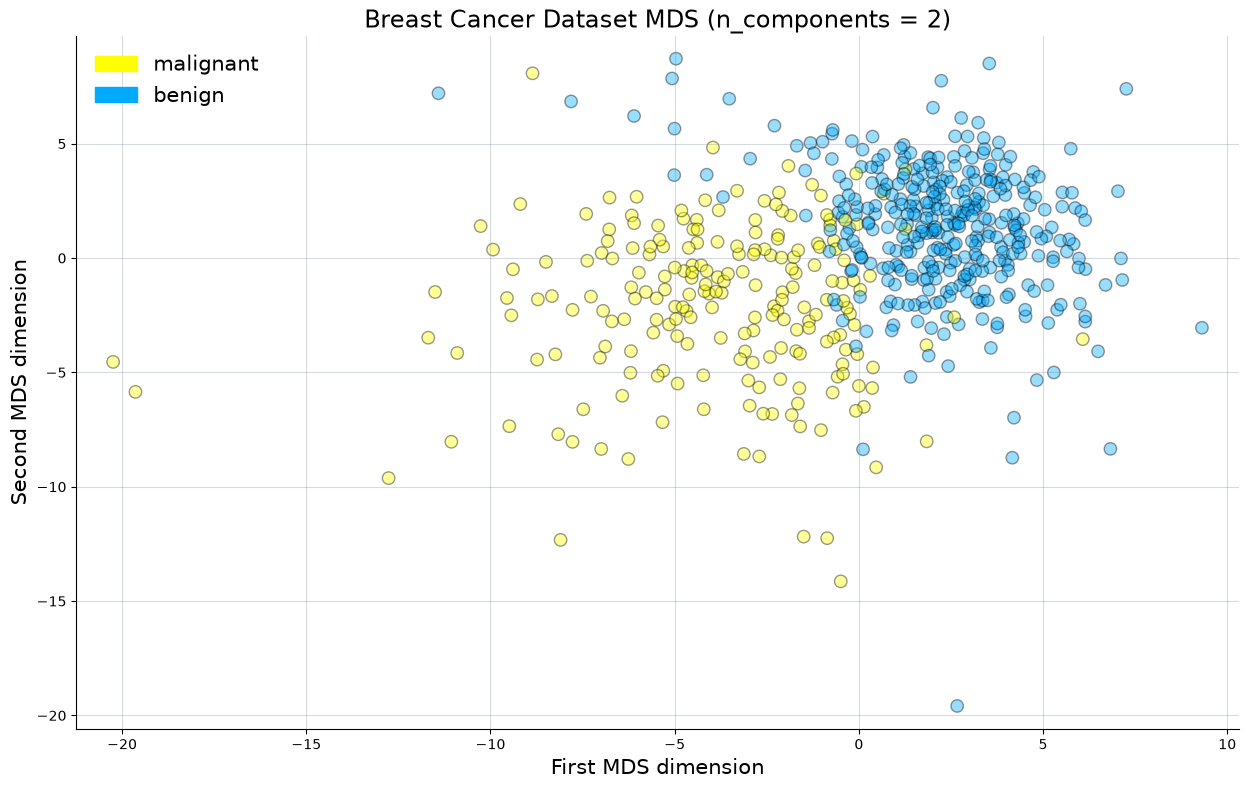

In [24]:
from sklearn.manifold import MDS

mds = MDS(n_components=2, random_state=2)     #이때 n_components = 2,random_state = 2로 두기

canc_mds = mds.fit_transform(canc_norm)

print('Number of Features in Breat Cancer DataSet Before MDS : {}\n\nNumber of Features in Breast Cancer DataSet After MDS : {}'
      .format(X_canc.shape[1],canc_mds.shape[1]))

plot_labelled_scatter(canc_mds, y_canc, ['malignant', 'benign'],(15,9))

plt.xlabel('First MDS dimension',fontsize=15)
plt.ylabel('Second MDS dimension',fontsize=15)
plt.title('Breast Cancer Dataset MDS (n_components = 2)',fontsize=17);

t-SNE 코드 완성하기

Number of Features in Breat Cancer DataSet Before T-SNE : 30

Number of Features in Breast Cancer DataSet After T-SNE : 2


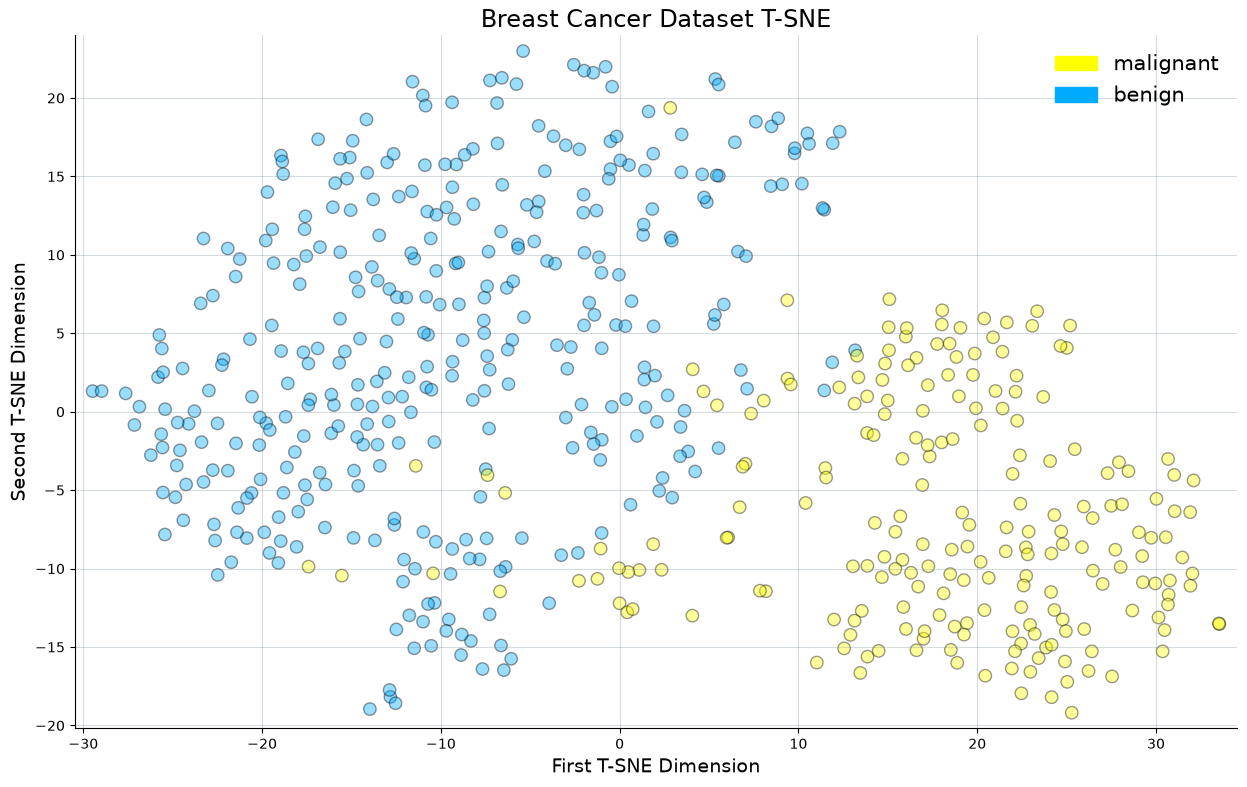

In [25]:
from sklearn.manifold import TSNE

tsne = TSNE(random_state=42)   #이때 random_state = 42로 두기

canc_tsne = tsne.fit_transform(canc_norm)

print('Number of Features in Breat Cancer DataSet Before T-SNE : {}\n\nNumber of Features in Breast Cancer DataSet After T-SNE : {}'
      .format(X_canc.shape[1],canc_tsne.shape[1]))

plot_labelled_scatter(canc_tsne, y_canc, ['malignant', 'benign'],(15,9))

plt.xlabel('First T-SNE Dimension',fontsize=14)
plt.ylabel('Second T-SNE Dimension',fontsize=14)
plt.title('Breast Cancer Dataset T-SNE',fontsize=17);

8-2) 세 기법의 차이를 간단히 서술하세요.

답 : pca는 데이터의 분산을 최대한 보존하는 방향으로 차원을 축소하는 선형 기법이다. 
mds, t-SNE는 데이터 간의 거리를 최대한 보존하도록 하는 비선형 차원 축소 기법이다. 특히 t-SNE는 주로 고차원 공간에 있는 샘플의 군집을 시각화할 때 사용된다. 